# 06 · Interpretation, risk tiers & retention

**Owner:** Sukhraj · **Phase 6** of the StayScope pipeline

Notebook 05 chose the final models. This notebook explains **why** they predict churn, and turns their
probabilities into something a retention team can use:

1. **Feature importance** for S and A with two methods: Random Forest impurity importance and SHAP on XGBoost.
2. **Common drivers:** which kinds of features drive churn in both datasets.
3. **Risk tiers:** low / medium / high churn risk, and what each tier looks like.
4. **Retention rules:** high-churn segments with a suggested action and a data-based rationale.

Experiments with final models in `final_models.json` are picked up automatically. The A_hard experiments appear here
once notebook 05 has trained them.

Logic: `src/churn/risk.py`. Outputs: `feature_importance.csv`, `risk_profiles.csv`, `retention_rules.json`.

## 1. Setup

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import display

from churn import config, data, models as M, risk as R
from churn.plotting import CHURN, MEDIUM, NEUTRAL, RETAINED, savefig, set_style

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
set_style()
config.ensure_dirs()
TARGET, ID = config.TARGET, config.ID_COL
TIER_COLORS = {"low": RETAINED, "medium": MEDIUM, "high": CHURN}
METHOD_COLORS = {"rf": "#2BB3A3", "shap": "#F5A524"}

experiments = list(M.load_final_config())
print("experiments with final models:", experiments)

experiments with final models: ['S_full', 'A_full']


## 2. Interpret every experiment

For each experiment: load (or train) the final models, compute RF importance on the whole model, SHAP on 2,000
test customers, and score the seed-0 test split with XGBoost for the risk tiers.

*Why SHAP on XGBoost, not on the Random Forest?* TreeSHAP's cost grows with the number of leaves. The final Random
Forest on S has 300 deep trees (depth 16), which would take hours; XGBoost's shallow trees take seconds. The two
models score almost the same on S (ROC-AUC 0.745 vs 0.748, notebook 05), and two different methods on two models that
agree give a more robust picture than one.

In [2]:
res = {e: R.interpret_experiment(e) for e in experiments}
importance = pd.concat([r["importance"] for r in res.values()], ignore_index=True)
importance.pivot_table(index="feature", columns=["experiment", "method"], values="importance").sort_values(
    ("S_full", "shap"), ascending=False)

experiment                  A_full       S_full      
method                          rf  shap     rf  shap
feature                                              
account_age                    NaN   NaN  0.233 0.220
avg_viewing_duration           NaN   NaN  0.160 0.162
content_downloads_per_month    NaN   NaN  0.115 0.138
viewing_hours_per_week         NaN   NaN  0.127 0.135
monthly_charges                NaN   NaN  0.096 0.105
support_tickets_per_month      NaN   NaN  0.052 0.086
subscription_type            0.049 0.135  0.018 0.043
payment_method               0.052 0.128  0.019 0.034
favorite_genre               0.020 0.009  0.019 0.024
watchlist_size                 NaN   NaN  0.033 0.018
user_rating                    NaN   NaN  0.048 0.018
content_type                   NaN   NaN  0.017 0.011
subtitles_enabled              NaN   NaN  0.008 0.004
gender                       0.014 0.007  0.013 0.001
parental_control               NaN   NaN  0.008 0.001
device                       0.019 0.005  0.018 0.000
multi_device_access            NaN   NaN  0.008 0.000
paperless_billing              NaN   NaN  0.008 0.000
age                          0.029 0.006    NaN   NaN
last_login_days              0.323 0.284    NaN   NaN
number_of_profiles           0.064 0.144    NaN   NaN
region                       0.020 0.008    NaN   NaN
watch_hours                  0.409 0.275    NaN   NaN

## 3. What drives churn in S (main dataset)?

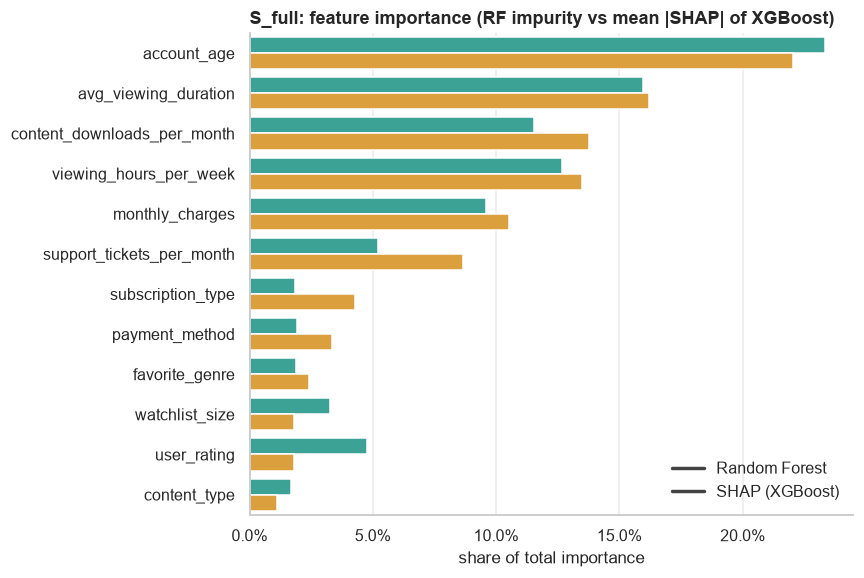

In [3]:
def importance_plot(exp, name, top=12):
    d = importance[importance["experiment"] == exp]
    order = d[d["method"] == "shap"].sort_values("importance", ascending=False)["feature"].head(top)
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(order) + 1.2))
    sns.barplot(d[d["feature"].isin(order)], y="feature", x="importance", hue="method", order=order,
                palette=METHOD_COLORS, ax=ax)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xlabel("share of total importance")
    ax.set_ylabel("")
    ax.set_title(f"{exp}: feature importance (RF impurity vs mean |SHAP| of XGBoost)")
    ax.legend(title="", labels=["Random Forest", "SHAP (XGBoost)"])
    fig.tight_layout()
    savefig(fig, name)

importance_plot("S_full", "06_s_importance")

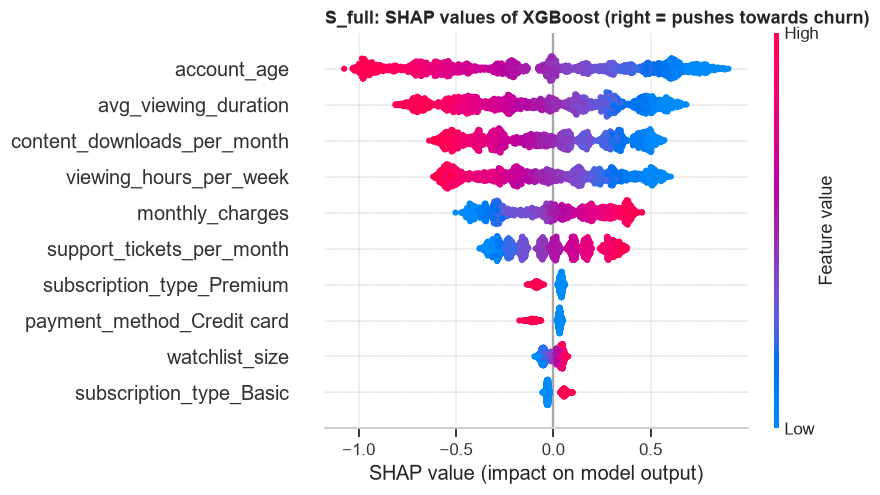

In [4]:
s_fit = res["S_full"]
cfg_s = M.load_final_config()["S_full"]["features"]
cols_s = [*cfg_s["numeric"], *cfg_s["categorical"], *cfg_s["binary"]]
sample_s = s_fit["scored"].sample(R.SHAP_SAMPLE, random_state=config.RANDOM_STATE)
sv_s, Xt_s = R.shap_values(s_fit["models"]["xgboost"], sample_s[cols_s])
shap.summary_plot(sv_s, Xt_s, max_display=10, show=False, plot_size=(8, 4.5))
fig = plt.gcf()
fig.axes[0].set_title("S_full: SHAP values of XGBoost (right = pushes towards churn)", loc="left", fontweight="bold")
savefig(fig, "06_s_shap_summary")
plt.show()

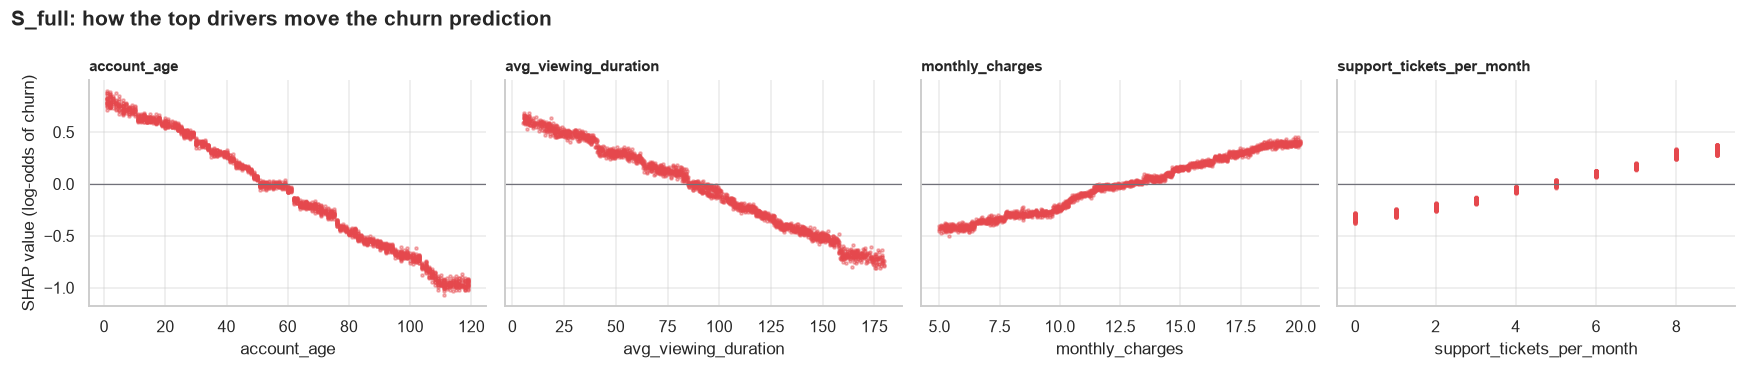

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, f in zip(axes, ["account_age", "avg_viewing_duration", "monthly_charges", "support_tickets_per_month"]):
    j = list(Xt_s.columns).index(f)
    ax.scatter(sample_s[f], sv_s[:, j], s=4, alpha=0.4, color=CHURN)
    ax.axhline(0, color=NEUTRAL, lw=0.8)
    ax.set_xlabel(f)
    ax.set_title(f, fontsize=10)
axes[0].set_ylabel("SHAP value (log-odds of churn)")
fig.suptitle("S_full: how the top drivers move the churn prediction", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "06_s_shap_dependence")

**S's churn drivers** (both methods agree on the top six, in almost the same order):

* **Tenure (`account_age`)** is the biggest driver: new customers churn far more, and the effect fades over the
  first few years.
* **Engagement:** short viewing sessions, few hours per week and few downloads all raise churn.
* **Price and friction:** a higher monthly charge and more support tickets raise churn.
* Plan, payment method, genre, device, gender and the Yes/No settings add almost nothing.

The SHAP dependence plots are close to straight lines. Each driver has a smooth, one-directional effect, which is why
Logistic Regression does as well as the tree ensembles on S (notebook 05).

## 4. What drives churn in A?

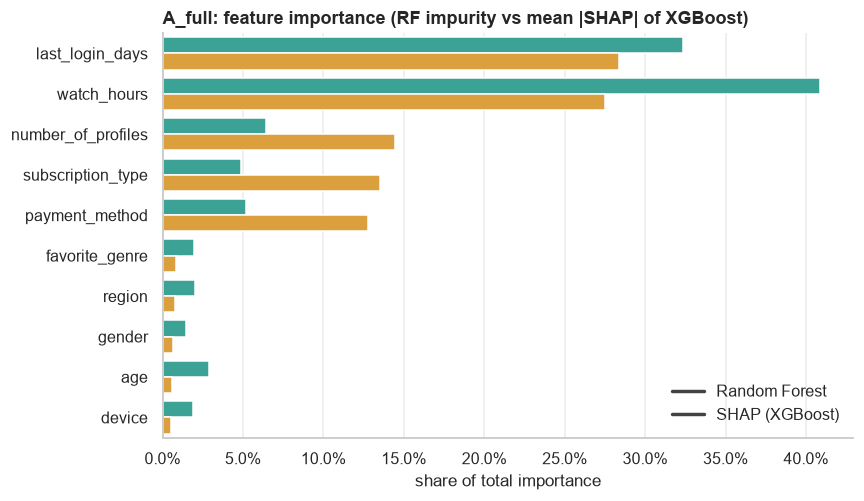

In [6]:
importance_plot("A_full", "06_a_importance")

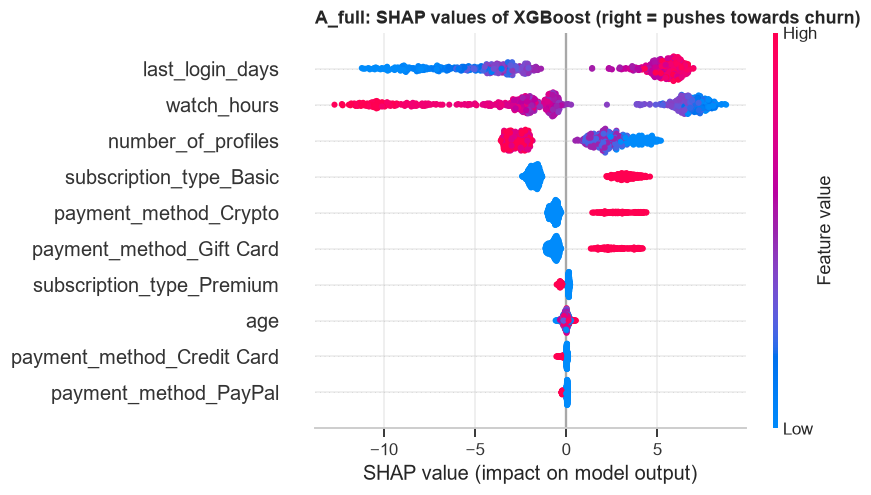

In [7]:
a_fit = res["A_full"]
cfg_a = M.load_final_config()["A_full"]["features"]
cols_a = [*cfg_a["numeric"], *cfg_a["categorical"], *cfg_a["binary"]]
sample_a = a_fit["scored"]
sv_a, Xt_a = R.shap_values(a_fit["models"]["xgboost"], sample_a[cols_a])
shap.summary_plot(sv_a, Xt_a, max_display=10, show=False, plot_size=(8, 4.5))
fig = plt.gcf()
fig.axes[0].set_title("A_full: SHAP values of XGBoost (right = pushes towards churn)", loc="left", fontweight="bold")
savefig(fig, "06_a_shap_summary")
plt.show()

**A's churn drivers:** engagement dominates. `watch_hours` and `last_login_days` together carry 56% (SHAP) to 73%
(Random Forest) of the importance. Next come the number of profiles, the plan (Basic churns more) and the payment method (crypto and
gift card churn more). Age, region, genre, device and gender add almost nothing.

## 5. Common drivers across datasets

The two datasets have different columns, so we compare them by **concept**. SHAP shares per concept:

In [8]:
CONCEPTS = {
    "engagement (viewing / activity)": {"S_full": ["avg_viewing_duration", "viewing_hours_per_week", "content_downloads_per_month"],
                                        "A_full": ["watch_hours", "last_login_days"]},
    "tenure": {"S_full": ["account_age"], "A_full": []},
    "price / plan": {"S_full": ["monthly_charges", "subscription_type"], "A_full": ["subscription_type"]},
    "payment method": {"S_full": ["payment_method"], "A_full": ["payment_method"]},
    "service friction (support)": {"S_full": ["support_tickets_per_month"], "A_full": []},
    "account set-up (profiles, devices, settings)": {"S_full": ["multi_device_access", "parental_control", "subtitles_enabled",
                                                     "paperless_billing", "device", "watchlist_size"],
                                                     "A_full": ["number_of_profiles", "device"]},
    "demographics & taste": {"S_full": ["gender", "favorite_genre", "content_type", "user_rating"],
                             "A_full": ["age", "gender", "region", "favorite_genre"]},
}
shap_imp = importance[importance["method"] == "shap"].set_index(["experiment", "feature"])["importance"]
concept = pd.DataFrame({e: {c: shap_imp.reindex([(e, f) for f in m[e]]).sum() for c, m in CONCEPTS.items()}
                        for e in ["S_full", "A_full"]})
assert np.allclose(concept.sum(), 1.0, atol=1e-6), "every feature must belong to one concept"
concept

,S_full,A_full
engagement (viewing / activity),0.434,0.559
tenure,0.220,0.000
price / plan,0.148,0.135
payment method,0.034,0.128
service friction (support),0.086,0.000
"account set-up (profiles, devices, settings)",0.023,0.150
demographics & taste,0.054,0.029


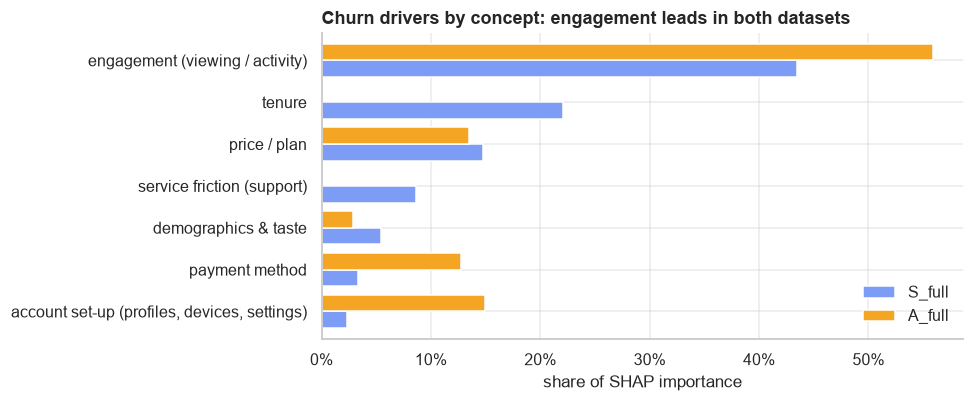

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
concept.sort_values("S_full").plot.barh(ax=ax, color={"S_full": "#7C9CF5", "A_full": "#F5A524"}, width=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("share of SHAP importance")
ax.set_title("Churn drivers by concept: engagement leads in both datasets")
fig.tight_layout()
savefig(fig, "06_common_drivers")

**Common driver: engagement.** In both datasets, how much and how recently a customer watches is the strongest churn
signal. In S it shares the top spot with **tenure**, which A does not record.

**Plan and payment matter in A, much less in S.** In A, Basic-plan and prepaid/crypto customers churn noticeably more;
in S these columns are weak, and S's price signal comes from the monthly charge, not the plan. A's
**number of profiles** (fewer profiles, more churn) has no counterpart in S.

**Demographics and taste barely matter in either dataset.** Gender, age, region, genre and device do not explain
churn. This is a useful message for a business: target customers on behaviour, not on who they are.

## 6. Risk tiers

Churn probability → **low** (< 0.3), **medium** (0.3–0.6), **high** (≥ 0.6), from `config.RISK_BINS`. The tiers use
the XGBoost model. On S it was trained without class weighting, so its probabilities are on the real scale (mean
≈ 0.18, the churn rate). The balanced models shift every probability upwards, which would put most customers in
the medium tier.

In [10]:
profiles = pd.concat([r["profiles"] for r in res.values()], ignore_index=True)
profiles[["experiment", "tier", "n_customers", "share", "mean_proba", "churn_rate"]]

,experiment,tier,n_customers,share,mean_proba,churn_rate
0,S_full,low,30295,0.828,0.133,0.131
1,S_full,medium,5970,0.163,0.397,0.414
2,S_full,high,304,0.008,0.653,0.655
3,A_full,low,364,0.485,0.013,0.000
4,A_full,medium,7,0.009,0.424,0.286
5,A_full,high,379,0.505,0.978,0.989


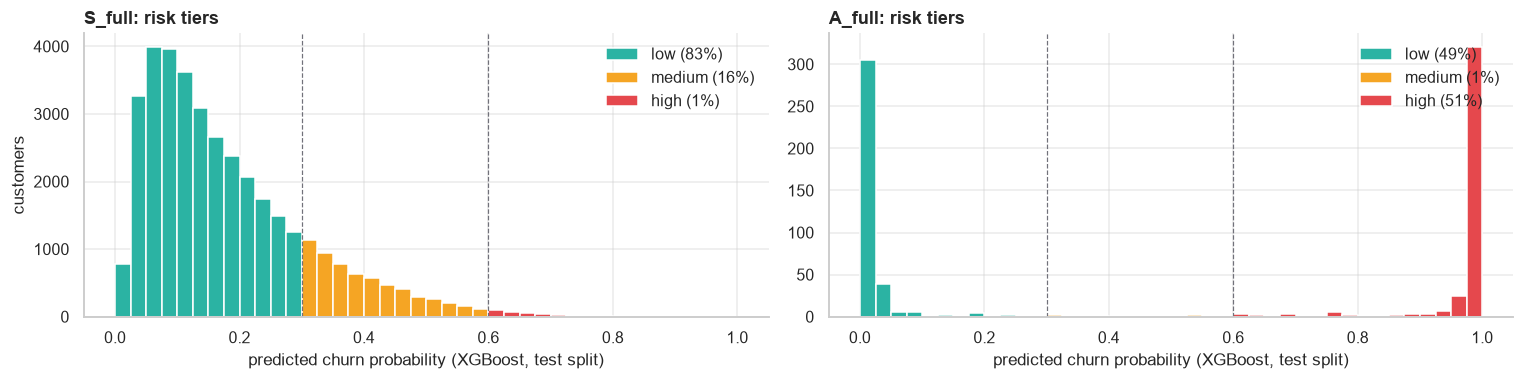

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, exp in zip(axes, ["S_full", "A_full"]):
    sc = res[exp]["scored"]
    bins = np.linspace(0, 1, 41)
    for tier, (lo, hi) in zip(config.RISK_LABELS, [(0, config.RISK_BINS[0]), config.RISK_BINS, (config.RISK_BINS[1], 1.01)]):
        d = sc[(sc["proba"] >= lo) & (sc["proba"] < hi)]
        ax.hist(d["proba"], bins=bins, color=TIER_COLORS[tier], label=f"{tier} ({len(d) / len(sc):.0%})")
    for b in config.RISK_BINS:
        ax.axvline(b, color=NEUTRAL, ls="--", lw=0.8)
    ax.set_xlabel("predicted churn probability (XGBoost, test split)")
    ax.set_title(f"{exp}: risk tiers")
    ax.legend()
axes[0].set_ylabel("customers")
fig.tight_layout()
savefig(fig, "06_risk_tiers")

In [12]:
s_prof = profiles[profiles["experiment"] == "S_full"].set_index("tier")
cols = ["churn_rate", "mean_account_age", "mean_avg_viewing_duration", "mean_viewing_hours_per_week",
        "mean_content_downloads_per_month", "mean_monthly_charges", "mean_support_tickets_per_month"]
display(s_prof[cols].T)
a_prof = profiles[profiles["experiment"] == "A_full"].set_index("tier")
a_prof[["churn_rate", "mean_watch_hours", "mean_last_login_days", "mean_number_of_profiles", "mean_age"]].T

tier,low,medium,high
churn_rate,0.131,0.414,0.655
mean_account_age,66.472,30.771,17.954
mean_avg_viewing_duration,98.644,60.347,40.205
mean_viewing_hours_per_week,21.808,14.711,7.814
mean_content_downloads_per_month,26.182,16.799,9.128
mean_monthly_charges,12.089,14.331,16.549
mean_support_tickets_per_month,4.308,5.371,6.868


tier,low,medium,high
churn_rate,0.000,0.286,0.989
mean_watch_hours,16.955,5.853,5.878
mean_last_login_days,21.486,14.286,38.892
mean_number_of_profiles,3.294,3.000,2.768
mean_age,45.368,42.429,44.148


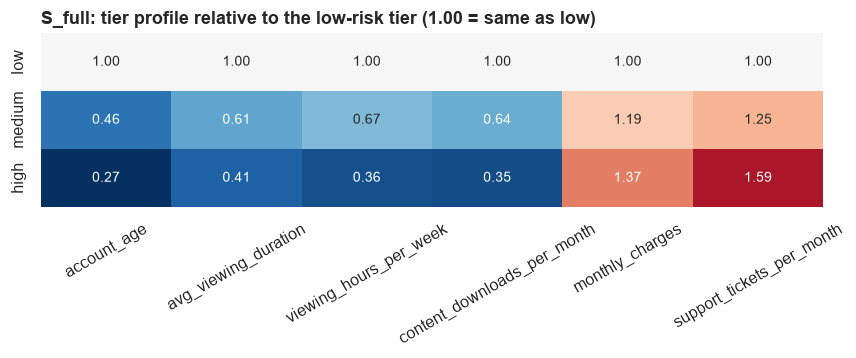

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.4))
s_prof_plot = s_prof[cols[1:]]
rel = s_prof_plot / s_prof_plot.loc["low"]  # each feature relative to the low-risk tier
rel.columns = [c.replace("mean_", "") for c in rel.columns]
sns.heatmap(rel, annot=True, fmt=".2f", cmap="RdBu_r", center=1, ax=ax, cbar=False, annot_kws={"size": 9})
ax.set_title("S_full: tier profile relative to the low-risk tier (1.00 = same as low)")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
savefig(fig, "06_s_tier_profiles")

**S:** the tiers are well calibrated: the mean predicted probability matches the observed churn rate in every tier.
About 83% of customers are low risk (13% churn), 16% medium (≈41%) and under 1% high (≈65%). The high tier is
**new, light-viewing, high-paying, frequent-support** customers: about a quarter of the low tier's tenure and less than
half its viewing time.

**A:** almost every customer is either low or high risk, because A is nearly perfectly predictable from engagement.
The high tier watches about a third as much and last logged in almost twice as long ago.

Because S's high tier is small, a retention team would normally target **high + the top of medium**. The budget
simulator in the app makes that threshold choice explicit.

## 7. Retention rules

Each rule is a segment with clearly higher churn, a suggested action, and the observed numbers behind it.
**These are associations, not proven effects.** An offer should be A/B tested before it is rolled out.

In [14]:
rules = R.build_retention_rules(data.load_clean_s(), data.load_clean_a())
rules_df = pd.DataFrame(rules)
rules_df[["dataset", "condition", "segment_churn_rate", "rest_churn_rate", "lift", "segment_share", "suggestion"]]

,dataset,condition,segment_churn_rate,rest_churn_rate,lift,segment_share,suggestion
0,S,account_age < 12,0.315,0.168,1.880,0.091,First-year onboarding: a welcome series and a ...
1,S,avg_viewing_duration < 30,0.269,0.167,1.610,0.144,Short sessions: surface personalised picks and...
2,S,viewing_hours_per_week < 5,0.268,0.171,1.560,0.102,Low viewing: send a re-engagement digest with ...
3,S,content_downloads_per_month < 5,0.266,0.172,1.550,0.100,Few downloads: promote offline viewing (downlo...
4,S,support_tickets_per_month >= 7,0.222,0.164,1.360,0.301,Many support tickets: proactive follow-up from...
5,S,monthly_charges >= 17,0.238,0.167,1.420,0.199,High bill: offer a loyalty discount or a cheap...
6,A,last_login_days > 30,0.751,0.261,2.880,0.494,Inactive for over a month: win-back email with...
7,A,watch_hours < 5,0.840,0.319,2.640,0.354,Very low watch time: guided content discovery ...
8,A,subscription_type == 'Basic',0.618,0.446,1.390,0.332,Basic plan: free trial of Standard features to...
9,A,"payment_method in ['Crypto', 'Gift Card']",0.588,0.448,1.310,0.394,Prepaid / non-recurring payment: nudge to swit...


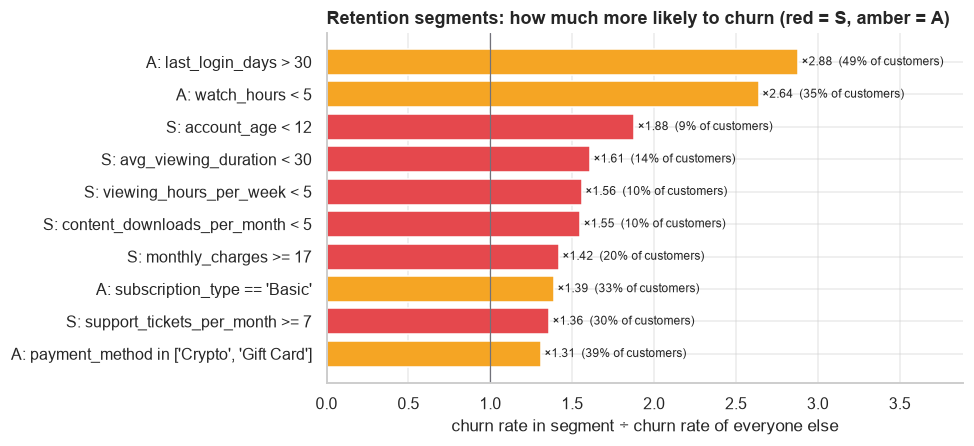

In [15]:
d = rules_df.assign(label=rules_df["dataset"] + ": " + rules_df["condition"]).sort_values("lift")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(d["label"], d["lift"], color=[CHURN if x == "S" else MEDIUM for x in d["dataset"]])
ax.axvline(1, color=NEUTRAL, lw=0.8)
for y, (lift, share) in enumerate(zip(d["lift"], d["segment_share"])):
    ax.text(lift + 0.02, y, f"×{lift:.2f}  ({share:.0%} of customers)", va="center", fontsize=8)
ax.set_xlabel("churn rate in segment ÷ churn rate of everyone else")
ax.set_title("Retention segments: how much more likely to churn (red = S, amber = A)")
ax.set_xlim(0, d["lift"].max() * 1.35)
fig.tight_layout()
savefig(fig, "06_retention_lift")

Suggestions for three test customers of S (highest, median and lowest risk). The app's Churn predictor shows the same:

In [16]:
sc = res["S_full"]["scored"].sort_values("proba")
for label, row in [("highest risk", sc.iloc[-1]), ("median risk", sc.iloc[len(sc) // 2]), ("lowest risk", sc.iloc[0])]:
    print(f"{label}: p = {row['proba']:.2f} ({R.assign_tier(row['proba'])}), churned = {row[TARGET]}")
    for s in R.retention_suggestions(row, rules) or ["no rule applies: no action needed"]:
        print("   -", s)

highest risk: p = 0.82 (high), churned = 0
   - High churn risk: prioritise this customer for a retention offer.
   - Short sessions: surface personalised picks and shorter formats on the home screen.
   - Low viewing: send a re-engagement digest with new releases in the customer's favourite genre.
   - Few downloads: promote offline viewing (download reminders before commutes and travel).
   - Many support tickets: proactive follow-up from the support team and a goodwill credit.
median risk: p = 0.15 (low), churned = 0
   - no rule applies: no action needed
lowest risk: p = 0.01 (low), churned = 0
   - no rule applies: no action needed


## 8. Save results

In [17]:
importance.to_csv(config.RESULTS_DIR / "feature_importance.csv", index=False)
profiles.to_csv(config.RESULTS_DIR / "risk_profiles.csv", index=False)
(config.RESULTS_DIR / "retention_rules.json").write_text(json.dumps(rules, indent=2))
for f in ["feature_importance.csv", "risk_profiles.csv", "retention_rules.json"]:
    print((config.RESULTS_DIR / f).relative_to(config.ROOT))

reports\results\feature_importance.csv
reports\results\risk_profiles.csv
reports\results\retention_rules.json


## 9. Key findings

1. **S's churn is driven by tenure and engagement.** Account age, average viewing duration, downloads and weekly
   viewing hours are the top four for both Random Forest importance and SHAP, followed by monthly charge and support
   tickets. Plan, payment, genre, device, gender and the account settings barely matter.
2. **A's churn is driven by engagement** (watch hours and days since last login), then the number of profiles, plan
   and payment method.
3. **The common driver is engagement.** Plan and payment method matter in A but much less in S, and demographics
   matter in neither. This also explains notebook 04: the columns the two datasets share are exactly the ones that
   carry little churn signal.
4. **Risk tiers on S are well calibrated** (predicted ≈ observed churn in every tier). High-risk customers are new,
   light viewers with higher bills and more support tickets.
5. **Ten retention rules** (6 for S, 4 for A) turn these drivers into actions, such as first-year onboarding,
   re-engagement for light viewers, proactive support and win-back for inactive users. Each comes with its observed
   lift and is labelled as an association to be tested, not a proven effect.